/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [16:20:24] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "n_neighbors" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


BAGGING Classifier Evaluation Metrics:
Accuracy: 0.8935
AUC: 0.9415
Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.95      0.92      4915
           1       0.87      0.77      0.82      2261

    accuracy                           0.89      7176
   macro avg       0.89      0.86      0.87      7176
weighted avg       0.89      0.89      0.89      7176


Sensitivity (Recall): 0.7744
Mean Absolute Error (MAE): 0.1065
Cohen's Kappa Score: 0.7455


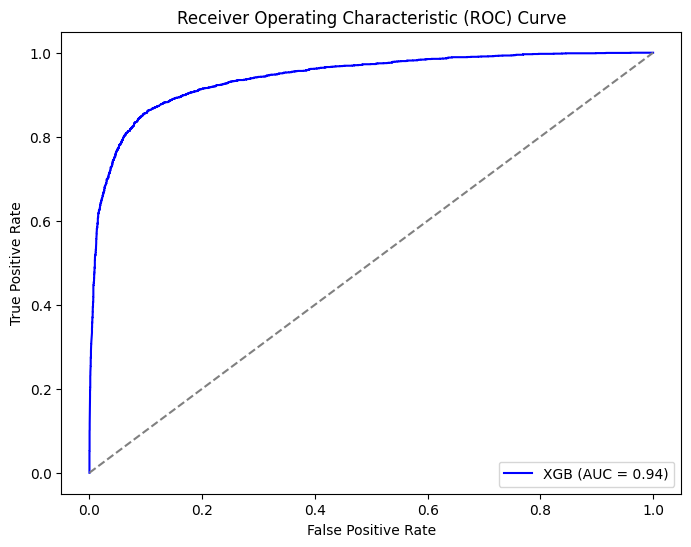

/tmp/ipython-input-2916128778.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics, y=values, palette="viridis")


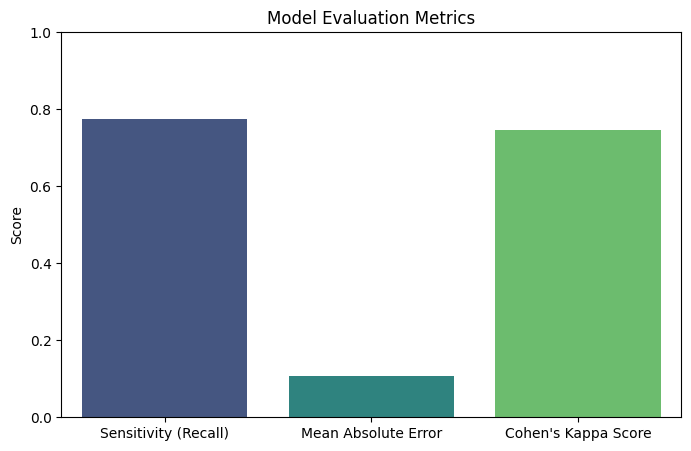

In [2]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, roc_auc_score, classification_report,
     mean_absolute_error, cohen_kappa_score, roc_curve, auc, recall_score
)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import random
import pandas as pd

# Set random seeds for reproducibility
np.random.seed(42)
random.seed(42)

# Load dataset
df = pd.read_csv('/content/Feature_selection_2.csv')
df

# Prepare data
df = df.drop('Unnamed: 0', axis=1)
X = df.drop(["class"], axis=1)
Y = df["class"]

# Train-Test Split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, stratify=Y, random_state=42)

# Initialize and Train BaggingClassifier
xgb = XGBClassifier(n_neighbors=5)
xgb.fit(X_train, Y_train)

# Predictions
y_pred = xgb.predict(X_test)
y_pred_proba = xgb.predict_proba(X_test)[:, 1]

# Evaluation Metrics
accuracy = accuracy_score(Y_test, y_pred)
auc_score = roc_auc_score(Y_test, y_pred_proba)
clf_report = classification_report(Y_test, y_pred)
sensitivity = recall_score(Y_test, y_pred) # Calculate sensitivity using recall_score
mae = mean_absolute_error(Y_test, y_pred) # Calculate MAE
kappa = cohen_kappa_score(Y_test, y_pred) # Calculate Cohen's Kappa

# Print Results
print("BAGGING Classifier Evaluation Metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"AUC: {auc_score:.4f}")
print(f"Classification Report:\n{clf_report}")
print(f"\nSensitivity (Recall): {sensitivity:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Cohen's Kappa Score: {kappa:.4f}")

# ROC Curve Plot
fpr, tpr, _ = roc_curve(Y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'XGB (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

# Bar Plot for Sensitivity, MAE, and Kappa Score
metrics = ["Sensitivity (Recall)", "Mean Absolute Error", "Cohen's Kappa Score"]
values = [sensitivity, mae, kappa]

plt.figure(figsize=(8, 5))
sns.barplot(x=metrics, y=values, palette="viridis")
plt.ylabel("Score")
plt.title("Model Evaluation Metrics")
plt.ylim(0, 1)  # Metrics are between 0 and 1
plt.show()

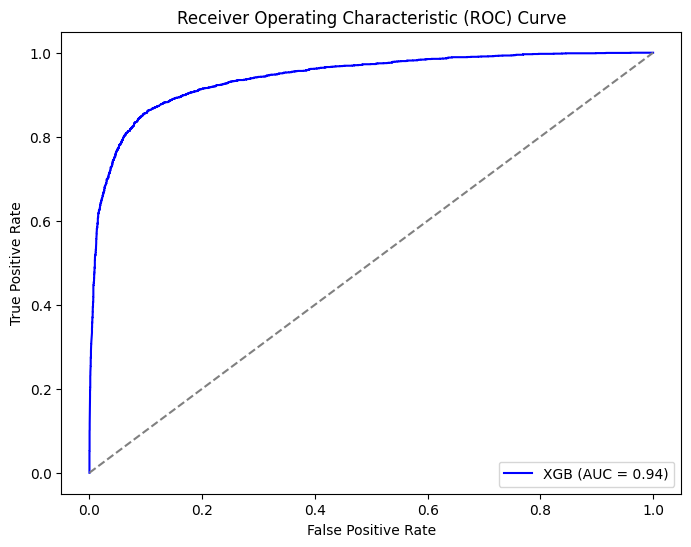

In [3]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'XGB (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')

# ✅ Added line to save ROC curve
plt.savefig("roc_curve_xgb.png", dpi=300, bbox_inches="tight")

plt.show()


/tmp/ipython-input-3564740000.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics, y=values, palette="viridis")


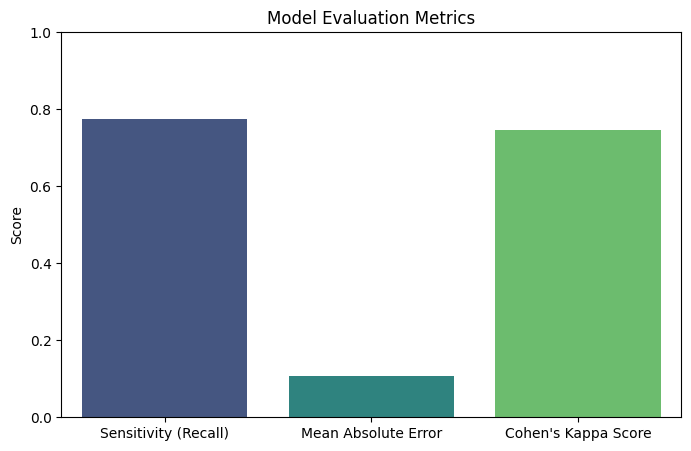

In [4]:
plt.figure(figsize=(8, 5))
sns.barplot(x=metrics, y=values, palette="viridis")
plt.ylabel("Score")
plt.title("Model Evaluation Metrics")
plt.ylim(0, 1)  # Metrics are between 0 and 1

# ✅ Added line to save bar plot
plt.savefig("model_evaluation_metrics_xgb.png", dpi=300, bbox_inches="tight")

plt.show()
